# LabLiquidVision

> Controlled lab images of single vessels (e.g., beakers/flasks) with varying liquid states and fill levels.

**GT available (per sample):**
- Vessel type (`vessel`)
- Liquid color (`color_liquid`)
- Liquid & vessel volumes in mL (`vol_liquid`, `vol_vessel`) → fill percentage
- Optional depth + masks (e.g., vessel/content masks, depth maps) when present

In [ ]:
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.append(str(Path("..") / "src"))
from datasets.labliquidvision import LabLiquidVisionDataset

ROOT = Path("..") / "data" / "LabLiquidVision" / "processed"
assert ROOT.exists(), f"Dataset root not found: {ROOT}"

all_ids = sorted([p.name for p in ROOT.iterdir() if p.is_dir()])
print(f"Dataset root: {ROOT}")
print(f"Total datapoints: {len(all_ids):,}")

Dataset root: ../data/LabLiquidVision/processed
Total datapoints: 5,595


## What is inside one datapoint?

Each sample folder typically includes:

- **Text metadata**: `vessel`, `color_liquid`, `vol_liquid`, `vol_vessel`
- **RGB image**: both `.png` and `.npy` variants
- **Depth and masks**: depth map, vessel mask, clean content mask, and segmented depth variants

So this is a **multi-modal perception dataset** for understanding container geometry and liquid content.

Top vessel categories by sample count:
- Cell_Flask_400mL: 678
- Gibco_500mL: 665
- Duran_500mL: 646
- Pyrex_100mL: 541
- Gibco_125mL: 524
- StorageBottle_500mL: 434
- Cell_Flask_160mL: 428
- Duran_250mL: 420
- StorageBottle_250mL: 413
- Tube_50mL: 369
- Duran_100mL: 347
- Tube_15mL: 130

Liquid volume distribution (parsed from folder names):
- min: 3.0 ml
- median: 132.0 ml
- max: 600.0 ml


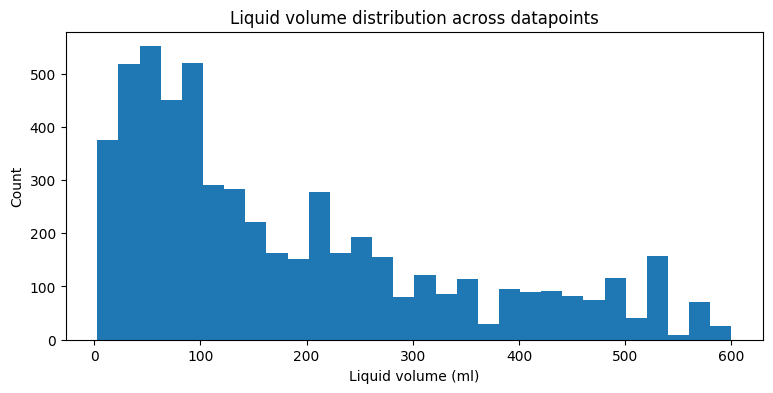

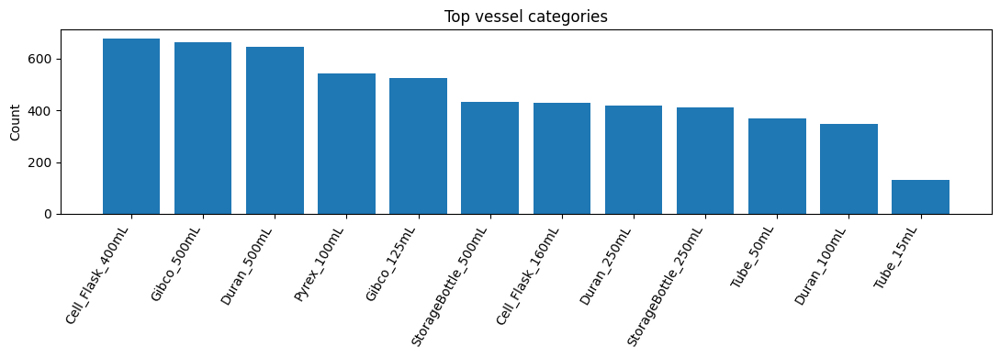

In [2]:
def parse_id(sample_id: str):
    # Expected pattern (example): Cell_Flask_160mL_31ml_1105_0605
    parts = sample_id.split("_")
    vessel = "_".join(parts[:-3]) if len(parts) >= 4 else sample_id
    fill_token = parts[-3] if len(parts) >= 3 else ""
    fill_ml = np.nan
    if fill_token.lower().endswith("ml"):
        try:
            fill_ml = float(fill_token[:-2])
        except ValueError:
            pass
    return vessel, fill_ml

vessel_counter = Counter()
fill_values = []

for sample_id in all_ids:
    vessel_name, fill_ml = parse_id(sample_id)
    vessel_counter[vessel_name] += 1
    if not np.isnan(fill_ml):
        fill_values.append(fill_ml)

print("Top vessel categories by sample count:")
for vessel_name, count in vessel_counter.most_common(12):
    print(f"- {vessel_name}: {count}")

if fill_values:
    fill_arr = np.array(fill_values)
    print("\nLiquid volume distribution (parsed from folder names):")
    print(f"- min: {fill_arr.min():.1f} ml")
    print(f"- median: {np.median(fill_arr):.1f} ml")
    print(f"- max: {fill_arr.max():.1f} ml")

plt.figure(figsize=(9, 4))
plt.hist(fill_values, bins=30)
plt.title("Liquid volume distribution across datapoints")
plt.xlabel("Liquid volume (ml)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(11, 4))
top_items = vessel_counter.most_common(12)
plt.bar([x[0] for x in top_items], [x[1] for x in top_items])
plt.title("Top vessel categories")
plt.xticks(rotation=60, ha="right")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

## Multi-modal view per datapoint

The next cells create **one chart per datapoint** where all available image-like modalities are shown together.

This is useful to compare:
- RGB appearance
- depth signals
- vessel mask and liquid-content mask
- segmented depth variants

In [3]:
def to_display_image(arr: np.ndarray):
    img = arr
    if img.ndim == 3 and img.shape[0] in (1, 3, 4) and img.shape[-1] not in (1, 3, 4):
        img = np.transpose(img, (1, 2, 0))
    if img.ndim == 3 and img.shape[-1] == 1:
        img = img[..., 0]
    return img


def show_datapoint_panel(sample_id: str):
    ds = LabLiquidVisionDataset(ROOT, ids=[sample_id])
    sample = ds[0]

    image_items = []
    for key, value in sample.items():
        if isinstance(value, np.ndarray):
            image_items.append((key, to_display_image(value)))

    image_items = sorted(image_items, key=lambda x: x[0])
    n = len(image_items)
    if n == 0:
        print(f"No array modalities found for {sample_id}")
        return

    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, (key, img) in zip(axes, image_items):
        if img.ndim == 2:
            ax.imshow(img, cmap="viridis")
        else:
            ax.imshow(img)
        ax.set_title(key)
        ax.axis("off")

    for ax in axes[n:]:
        ax.axis("off")

    vessel = sample.get("vessel", "unknown")
    vol_liquid = sample.get("vol_liquid", "?")
    vol_vessel = sample.get("vol_vessel", "?")
    color_liquid = sample.get("color_liquid", "?")

    fig.suptitle(
        f"{sample_id}\n"
        f"vessel={vessel} | color={color_liquid} | "
        f"vol_liquid={vol_liquid} | vol_vessel={vol_vessel}",
        y=1.02,
    )
    plt.tight_layout()
    plt.show()

Representative datapoints:
- Cell_Flask_160mL_110ml_1105_1009
- Cell_Flask_400mL_103ml_0905_2742
- Duran_100mL_108ml_0905_3629
- Duran_250mL_106ml_1105_2629
- Duran_500mL_113ml_2404_4244
- Gibco_125mL_109ml_0905_4427
- Gibco_500mL_118ml_0905_3926
- Pyrex_100mL_102ml_2404_5151


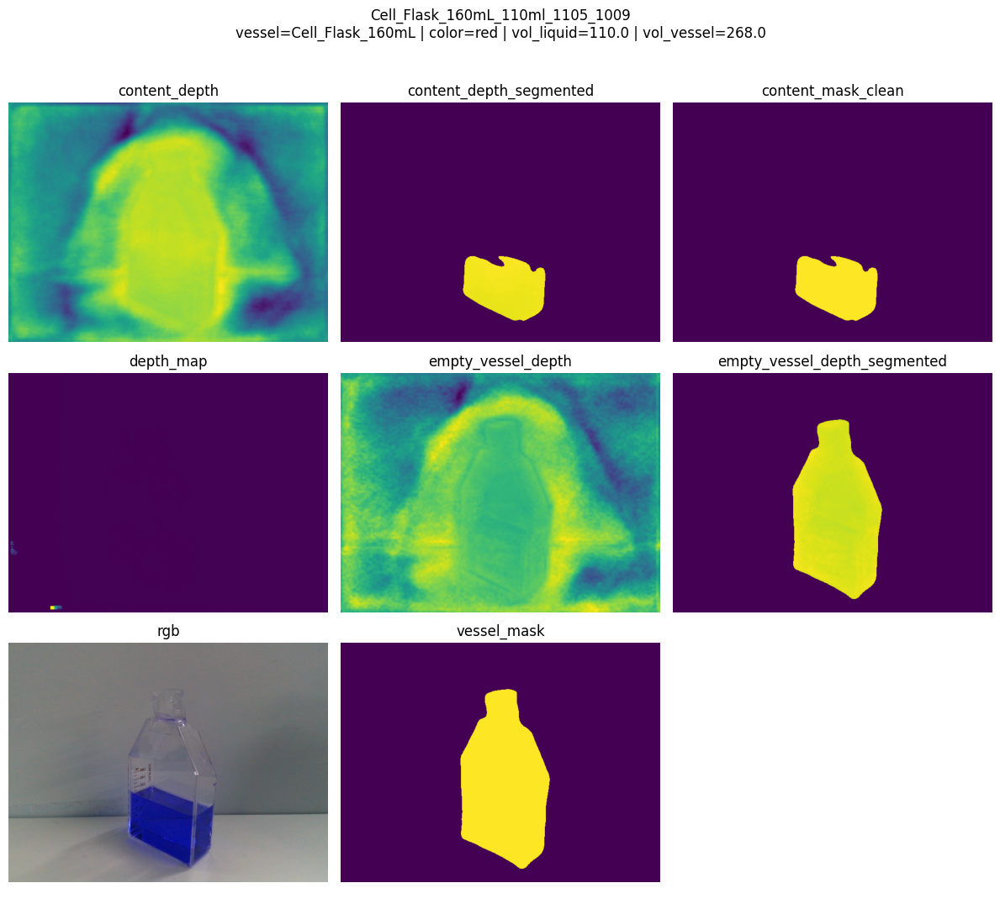

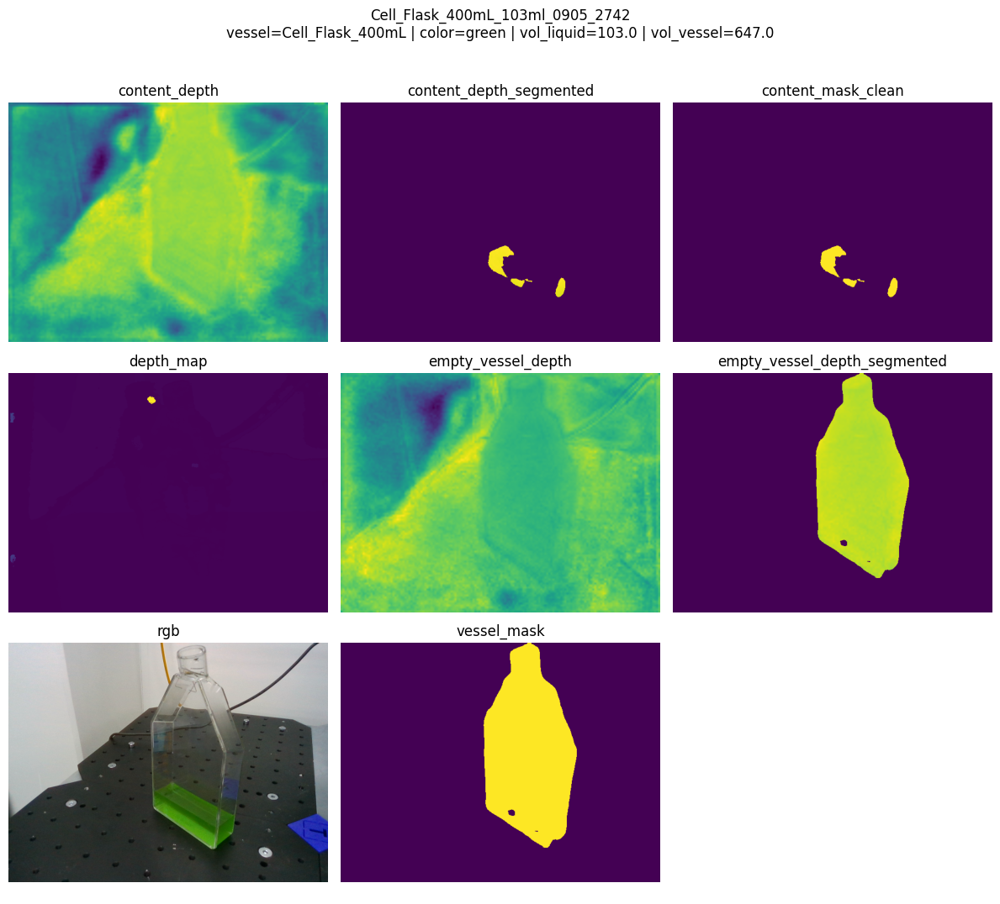

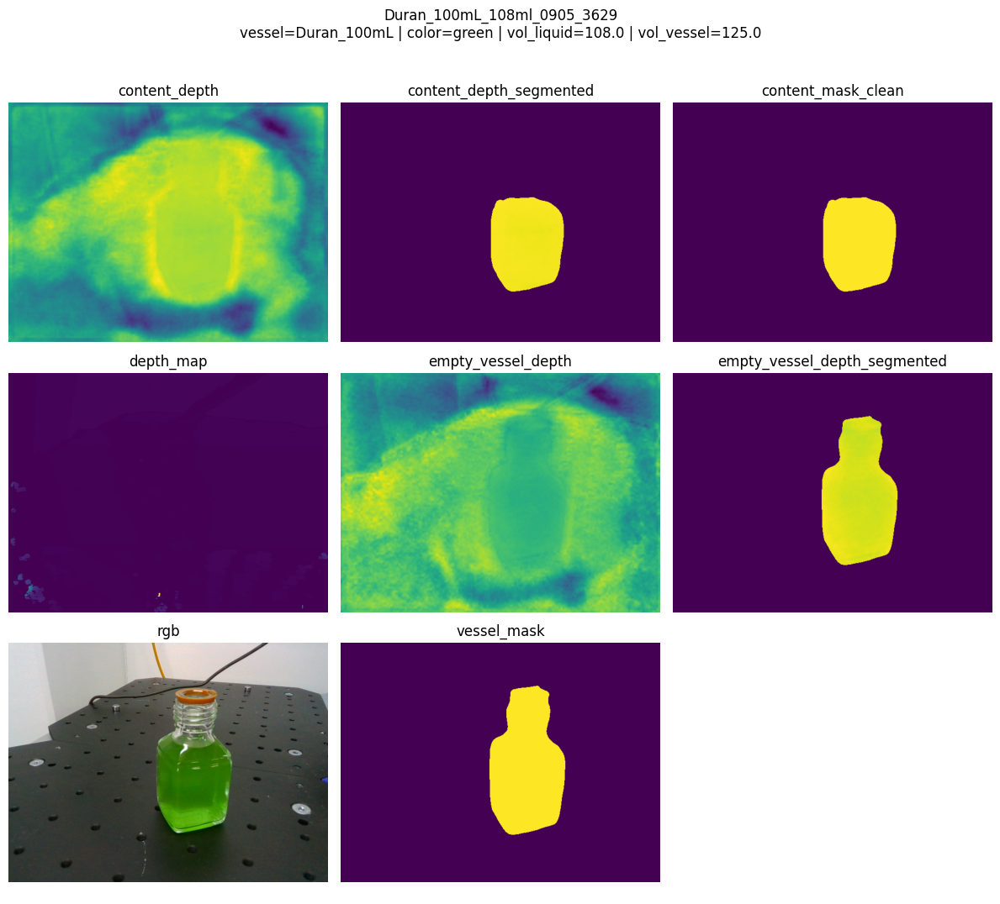

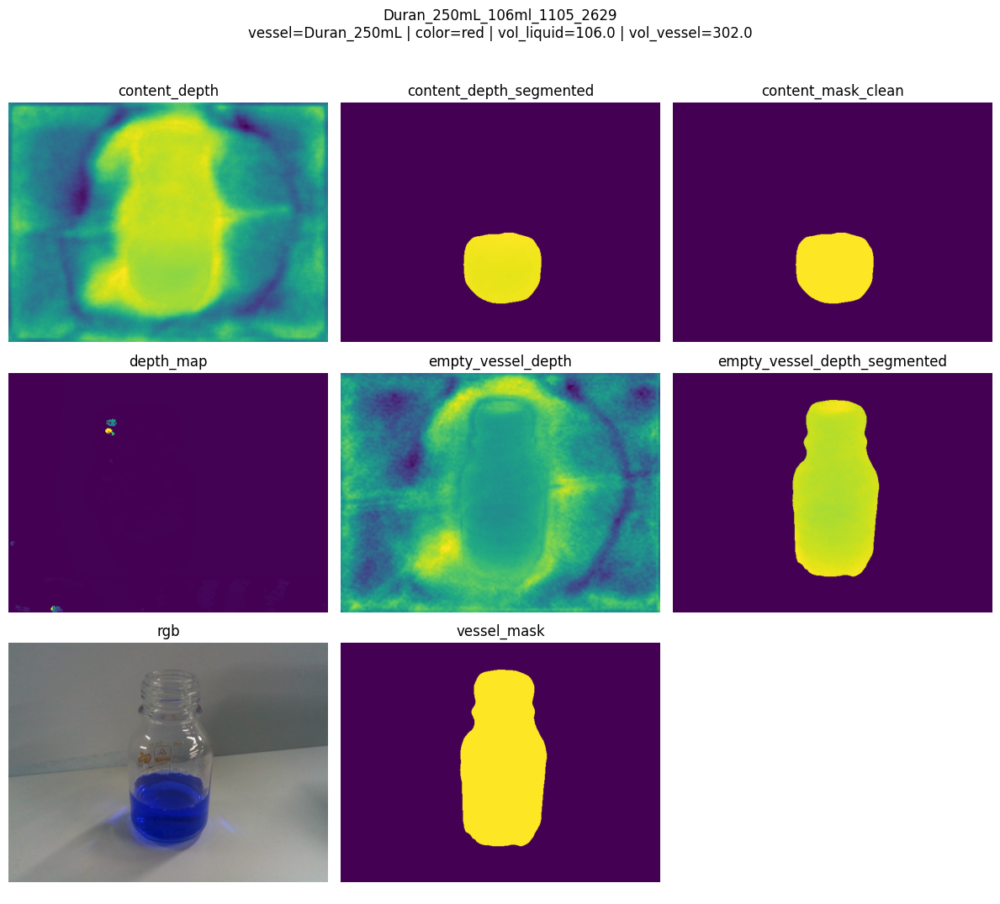

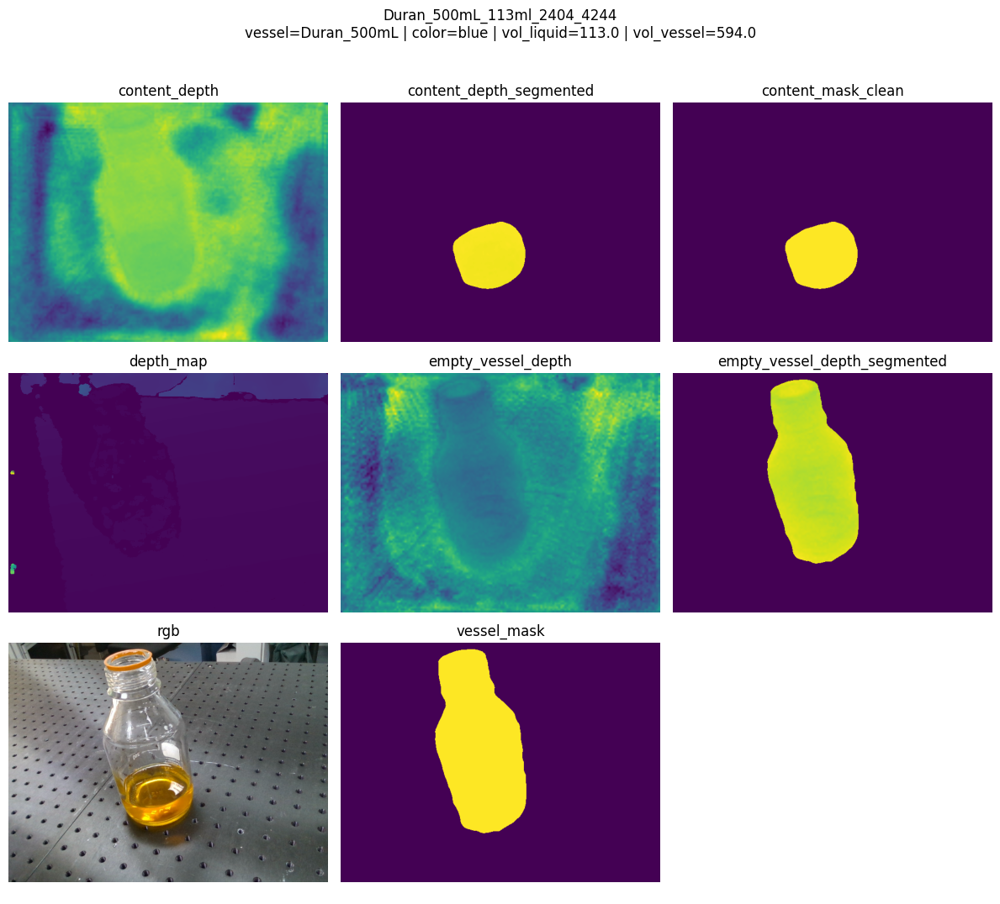

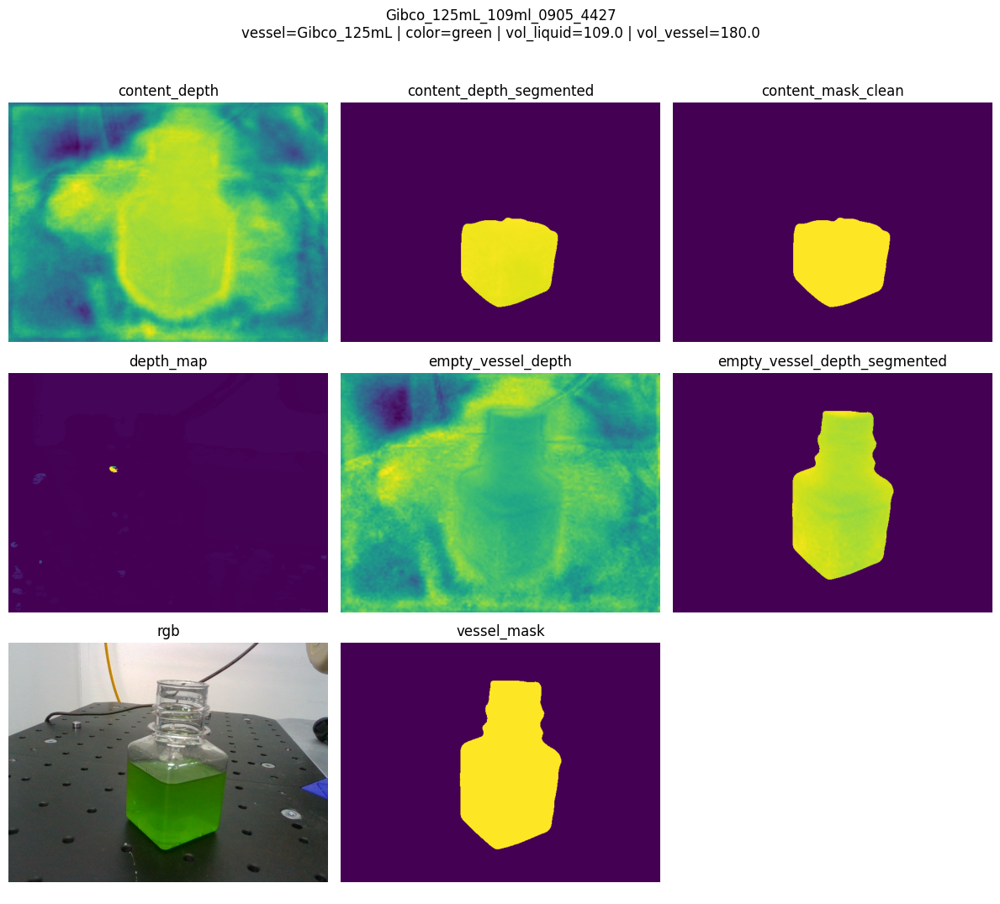

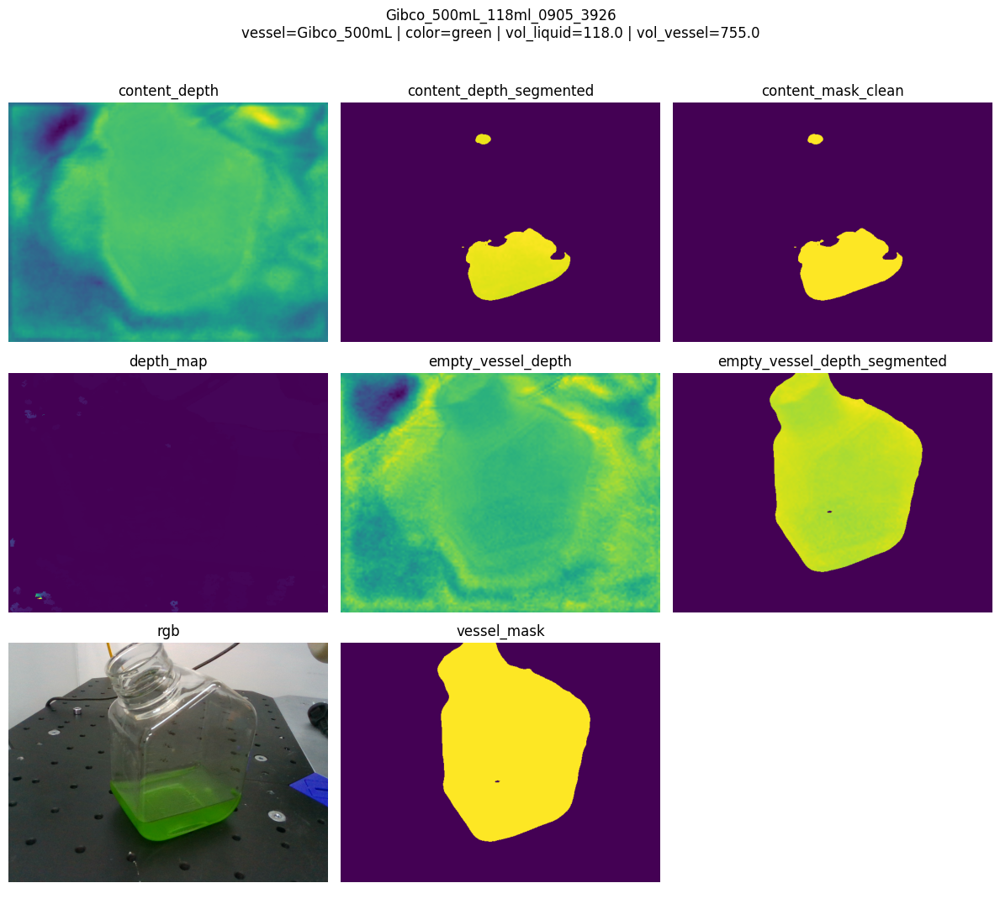

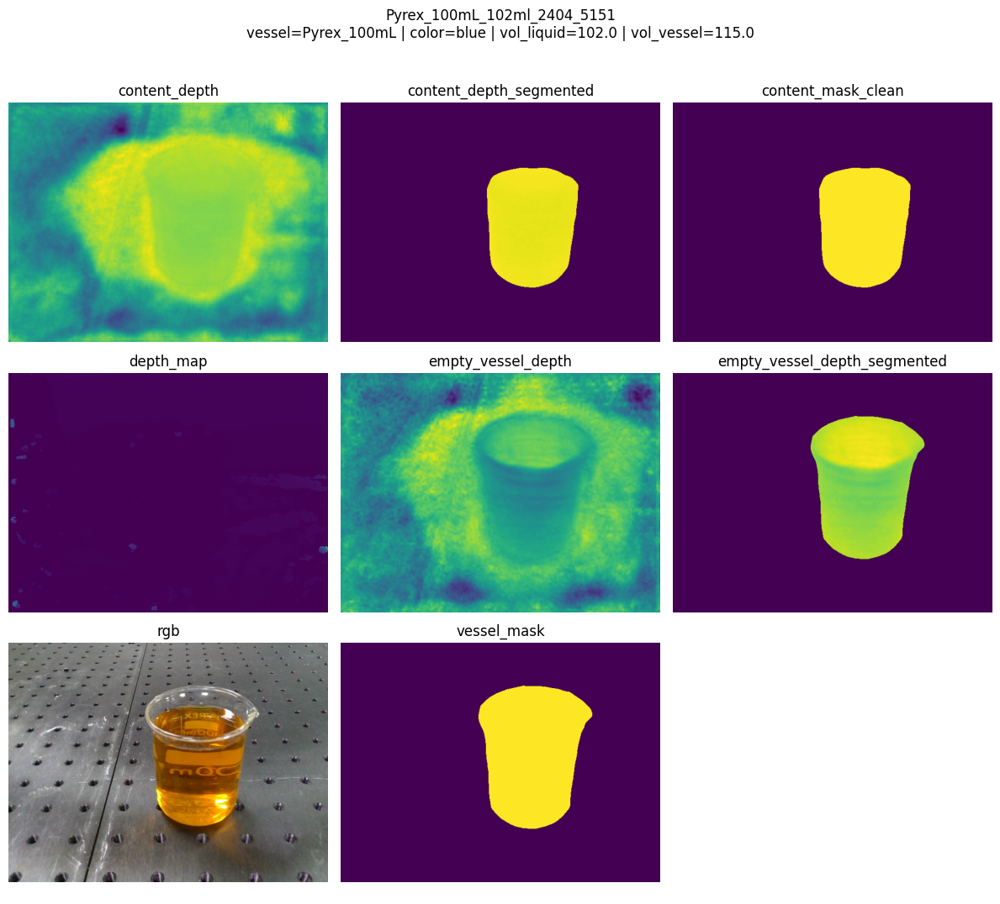

In [4]:
# Select representative datapoints from multiple vessel groups and fill levels
selected_ids = []
seen_vessels = set()

for sample_id in all_ids:
    vessel_name, _ = parse_id(sample_id)
    if vessel_name not in seen_vessels:
        selected_ids.append(sample_id)
        seen_vessels.add(vessel_name)
    if len(selected_ids) >= 8:
        break

print("Representative datapoints:")
for sample_id in selected_ids:
    print("-", sample_id)

for sample_id in selected_ids:
    show_datapoint_panel(sample_id)

## RGB gallery by vessel type

This gallery shows many datapoints at once (RGB only), grouped by vessel category.

It helps quickly communicate appearance diversity: different vessel geometries, fill levels, backgrounds, and viewpoints.

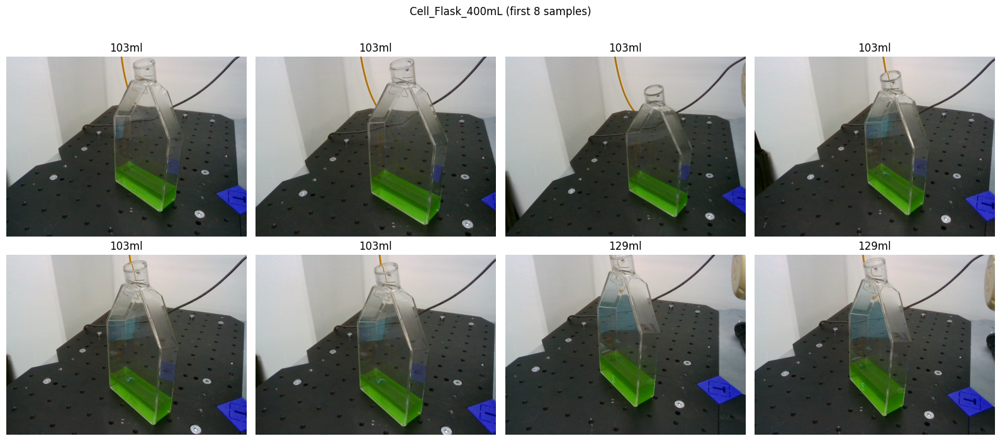

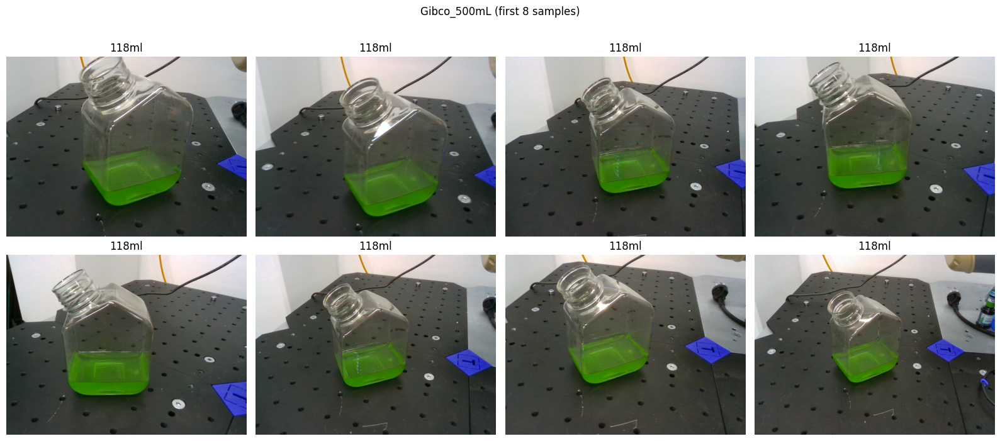

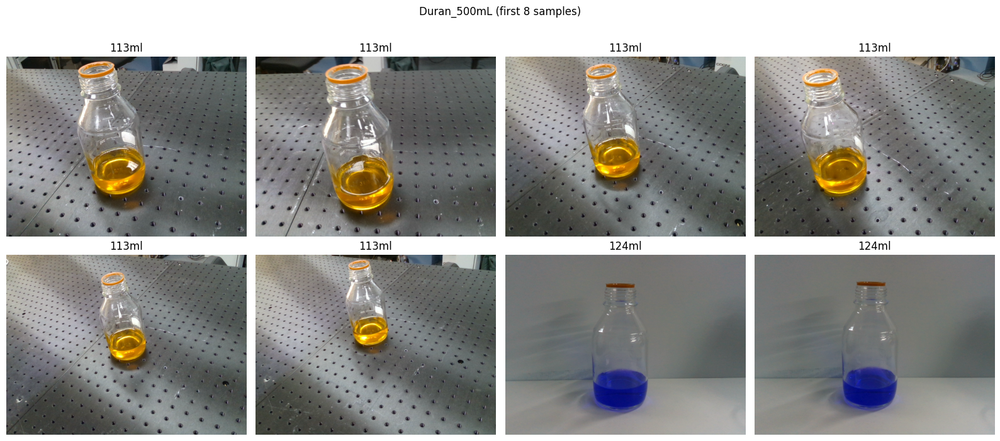

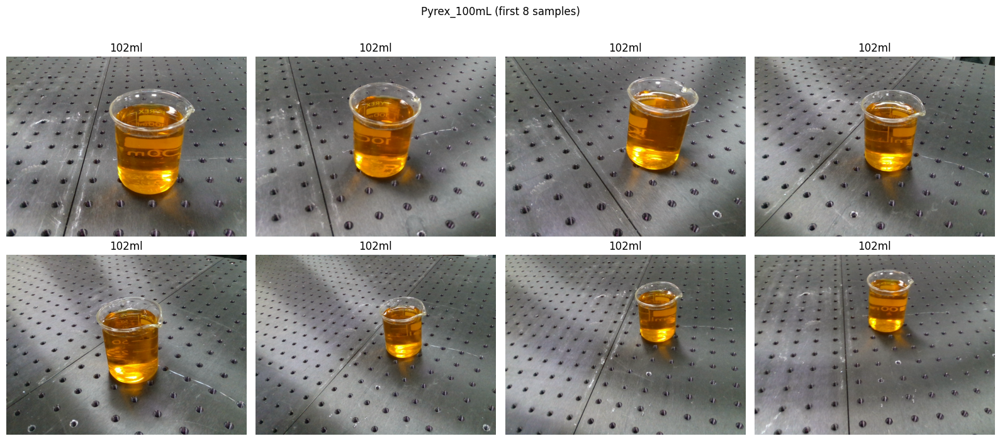

In [5]:
def show_rgb_gallery_for_vessel(vessel_name: str, max_images: int = 8):
    vessel_ids = [sample_id for sample_id in all_ids if parse_id(sample_id)[0] == vessel_name][:max_images]
    if not vessel_ids:
        print(f"No samples for {vessel_name}")
        return

    ds = LabLiquidVisionDataset(ROOT, ids=vessel_ids)

    cols = 4
    rows = int(np.ceil(len(vessel_ids) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.5 * rows))
    axes = np.array(axes).reshape(-1)

    for ax, sample in zip(axes, ds):
        rgb = sample.get("rgb")
        if isinstance(rgb, np.ndarray):
            img = to_display_image(rgb)
            ax.imshow(img)
        else:
            ax.text(0.5, 0.5, "rgb missing", ha="center", va="center")
        ax.set_title(sample["id"].split("_")[-3])
        ax.axis("off")

    for ax in axes[len(vessel_ids):]:
        ax.axis("off")

    fig.suptitle(f"{vessel_name} (first {len(vessel_ids)} samples)", y=1.02)
    plt.tight_layout()
    plt.show()

for vessel_name, _ in vessel_counter.most_common(4):
    show_rgb_gallery_for_vessel(vessel_name, max_images=8)

## Takeaways

- LabLiquidVision is a large multi-modal dataset with broad vessel and fill-level coverage.
- Each datapoint combines RGB + depth + masks + textual attributes.
- The one-panel-per-datapoint view is useful for quality checks and demos.

You can now use this notebook as a dataset presentation before model experiments.